# Simulated data with varying "OU" process



In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


header_setting.py: using old naming


## Predictions simulated data


In [2]:
# get files

directory = '../../data_realtrace_paper/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/'
sample = directory.split("/")[-2]

paramter_settings = {'mean_lambda': 'free',
                    'gamma_lambda': 'free',
                    'var_lambda': 'free',
                    'mean_q': 'free',
                    'gamma_q': 'free',
                    'var_q':'free',
                    'beta':'fixed',
                    'var_x':'free',
                    'var_g':'free',
                    'var_dx':'free',
                    'var_dg':'free'} 


paramter_settings_list = [paramter_settings]
filebase = default_filebase(directory, sample) # default

dat_file = directory + sample + ".csv"
prediction_file_f, prediction_file_b, prediction_file = get_prediction_files(filebase, paramter_settings_list)
iter_file, final_file = get_minimization_file(filebase, paramter_settings)

indata = pd.read_csv(dat_file, dtype={"parent_id":str, "cell_id":str})
prediction = pd.read_csv(prediction_file, skiprows=header_lines(prediction_file), 
                         dtype={"parent_id":str, "cell_id":str})

cells_true = df2cells(indata, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")

cells_prediction = ggp_df2cells(prediction, time="time", log_length="mean_x", gfp="mean_g", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="mean_l", qt="mean_q")

cells_noise = df2cells(indata, time="time_min", log_length="log_length_noise", gfp="gfp_noise", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")


full_data = pd.read_csv(directory + sample + "_full.csv", 
                       dtype={"parent_id":str, "cell_id":str})

cells_full = df2cells(full_data, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")



In [3]:

def get_path_idx(cells, idx0=0):
    idx = []
    last_cell = cells[idx0].parent_id
    for i, _ in enumerate(cells):
        if last_cell == cells[i].parent_id: 
            last_cell = cells[i].cell_id
            idx.append(i)
    return idx

def gaussian(x, y):
    mean = np.mean(y)
    sigma = np.std(y)
    return 1./(np.sqrt(2*np.pi)*sigma) * np.exp(-(x-mean)**2/(2*sigma**2))


def gauss_function(x, a, x0, sigma):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_6028/2466797809.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


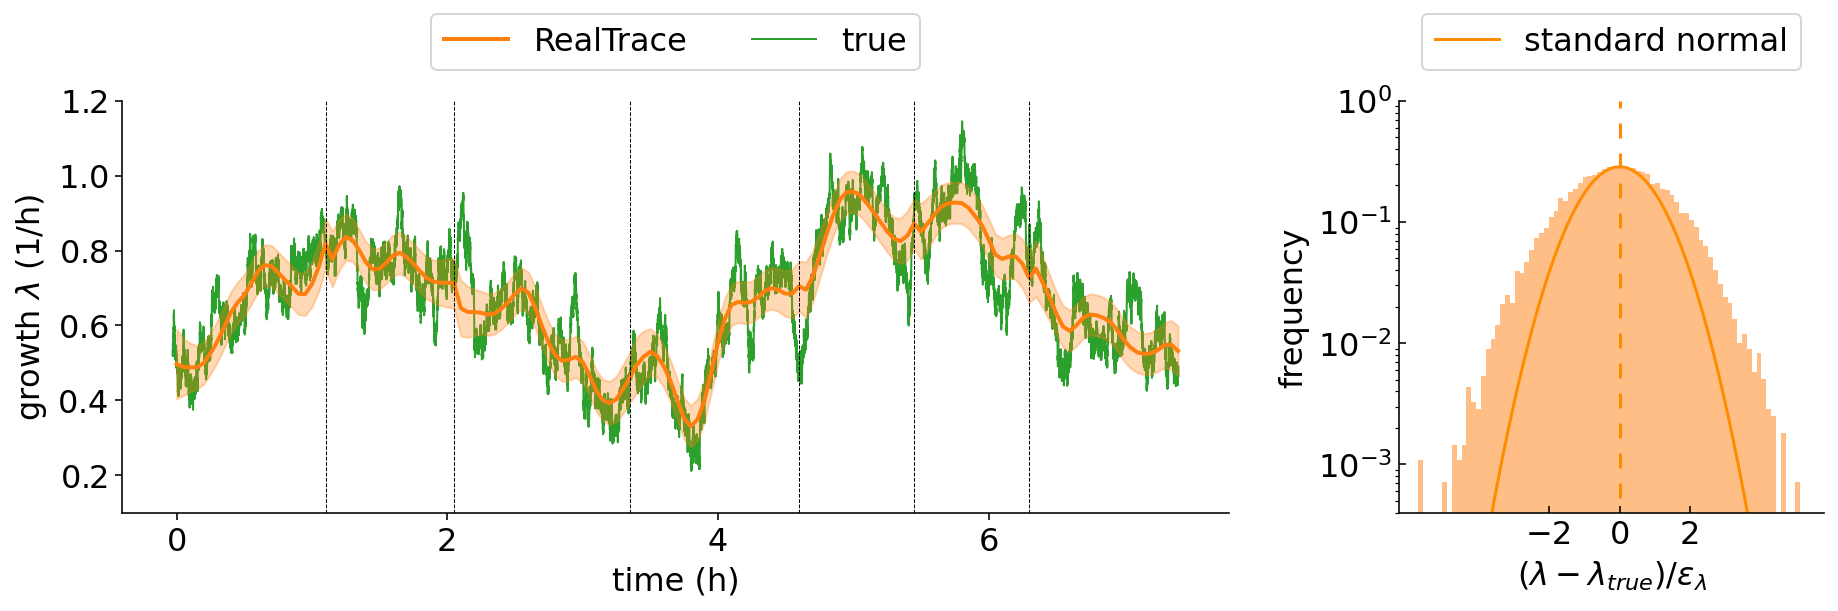

/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_6028/2466797809.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


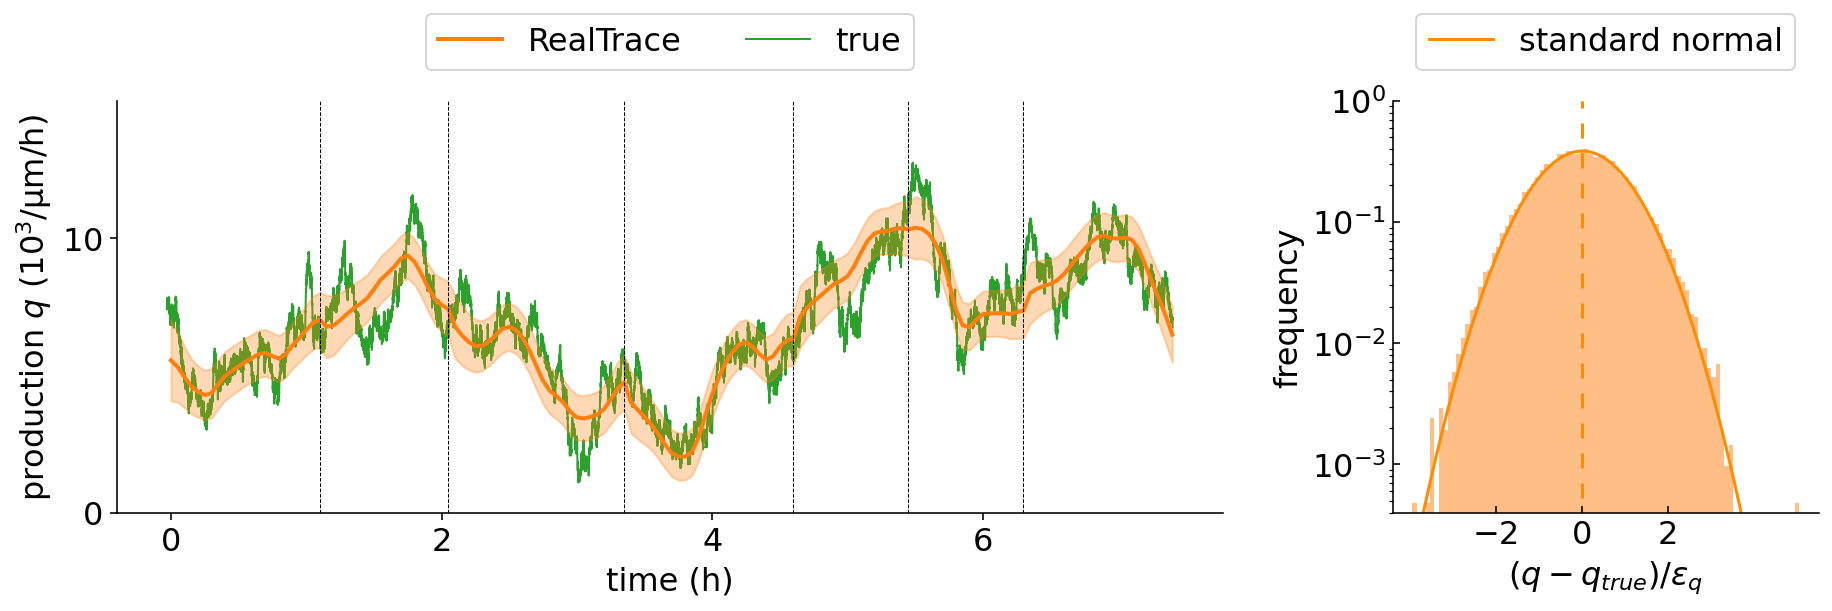

In [7]:
%load_ext autoreload
%autoreload 2



def plot_rate_residual(cells_true, cells_prediction, cells_noise, idx_cells, quantity, cells_full=None,  
                title="", xlim=[None, None], ylim=[None, None], plot_file=None, beta=0, fit_gaussian=True):
    # definitions for the axes

    left, width = 0.1, 0.65
    bottom, height = 0.1, 0.65
    spacing = 0.1

    hist_width = 0.25
    
    rect_scatter = [left, bottom, width, height]
    rect_histy = [left + width + spacing, bottom, hist_width, height]

    tot_width = rect_histy[0] + rect_histy[2]
    fig = plt.figure(figsize=(FULL_SIZE/tot_width, 1.1*FULL_HEIGHT))    
    
    ax = plt.axes(rect_scatter)

    ax_histy = plt.axes(rect_histy)
    ax_histy.tick_params(direction='in', labelleft=True)
    # ax_histy.set_title("distribution")
    
    # ax.set_title("cell lineage for synthetic data")    
    for a in [ax, ax_histy]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        # turn off the right spine/ticks
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        # turn off the top spine/ticks
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        # remove first tick
        # a.xaxis.get_major_ticks()[0].set_visible(False)
        
    ax_histy.set_ylabel("frequency")
    if quantity == "lambda":
        ax_histy.set_xlabel(r"$(\lambda - \lambda_{true})/\varepsilon_\lambda$")
        
    elif quantity =="q":
        ax_histy.set_xlabel(r"$(q - q_{true})/\varepsilon_q$")


    ###
    ax.set_xlabel("time (h)")
    ax.set_ylabel(title)

    label_cd = "cell division"
    label_p = "RealTrace"
    label_t = "true"
    label_n = "naive"

    prediction_coll = []
    noise_coll = []
    err_coll = []
    time_prediction_coll = []
    true_coll = []
    time_true_coll = []

    
    for i, _ in enumerate(cells_noise):
        if quantity == "lambda":
            prediction = np.array(cells_prediction[i].lt)
            err = np.sqrt(cells_prediction[i].cov_ll)
            true = np.array(cells_true[i].lt)
            
        elif quantity =="q":
            prediction = np.array(cells_prediction[i].qt)/1e3
            err = np.sqrt(cells_prediction[i].cov_qq)/1e3
            true = np.array(cells_true[i].qt)/1e3
            
             
        # prediction
        time_true_coll.append(cells_prediction[i].time)
        time_prediction_coll.append(cells_prediction[i].time)
        prediction_coll.append(prediction)
        err_coll.append(err)
        
        # truth
        true_coll.append(true)
    
    time_full_coll = []
    full_coll = []
    
    if cells_full!=None:
        for i, _ in enumerate(cells_full):
            if quantity == "lambda":
                full = np.array(cells_full[i].lt)
            elif quantity =="q":
                full = np.array(cells_full[i].qt)/1e3   

            time_full_coll.append(cells_full[i].time)
            full_coll.append(full)
            
    # # noise
    # if quantity == "lambda":
    #     naive_cells = naive_rate_for_all_cells(cells_noise, 1, naive_growth_rate_skip_div)
    # elif quantity =="q":
    #     naive_cells = naive_rate_for_all_cells(cells_noise, 1, naive_production_rate, beta)

    # time_noise_coll = [cell.time_naive_rate for cell in naive_cells]
    
    # if quantity == "lambda":
    #     noise_coll = [cn.naive_rate for cn in naive_cells]
    # elif quantity =="q":
    #     noise_coll = [cn.naive_rate/1e3 for cn in naive_cells]

    
    # Plots
    traces_time = index_nested(time_prediction_coll, idx_cells, True)
    time_shift= traces_time[0]
    # time_shift =0
    
    ax.plot( (traces_time - time_shift)/60., 
             (index_nested(prediction_coll, idx_cells, True))*60, 
             color='tab:orange',  label=label_p, alpha=1, zorder=2,lw=2)

    ax.fill_between( (traces_time-time_shift)/60., 
                     (deep_flatten(index_nested(prediction_coll, idx_cells, True))-deep_flatten(index_nested(err_coll, idx_cells, True)))*60, 
                     (deep_flatten(index_nested(prediction_coll, idx_cells, True))+deep_flatten(index_nested(err_coll, idx_cells, True)))*60, 
                       color="tab:orange", alpha=0.3, zorder=2)
    

    ax.plot( (index_nested(time_full_coll, idx_cells, True)-time_shift)/60., 
             index_nested(full_coll, idx_cells, True)*60., 
             color='tab:green',  label=label_t, alpha=1, lw=1, zorder=1)



    # time = index_nested(time_full_coll, idx_cells, True)/60.
    # mean = np.mean(np.concatenate(full_coll))*60
    # a = 0.5
    # T = 4
    # varying_mean = mean*(1+a*np.sin(2*np.pi/T*time))
    # ax.plot( time - time_shift/60., varying_mean, 
    #          color='tab:blue',  label="varying mean of OU process", alpha=1, lw=1, zorder=1)

    
    # ax.plot( (index_nested(time_noise_coll, idx_cells, True)-time_shift)/60., 
    #          index_nested(noise_coll, idx_cells, True)*60., 
    #          color='tab:grey', lw=1, label=label_n, alpha=1, ls='-', zorder=1)

    
    # cell division
    for i in idx_cells[:-1]:
        ax.axvline( (cells_prediction[i].time[-1]-time_shift)/60.,color='black', ls='--', lw=0.5)
        label_cd = None

    if xlim!=[None,None]:
        ax.set_xlim(xlim)
    if ylim!=[None,None]:
        ax.set_ylim(ylim)
    ax.ticklabel_format(axis='y', style='scientific', scilimits=[-4,4], useMathText=True)

        
    ############################################
    ############################################
    # Hist
    ############################################
    ############################################
    ## true
    z_stat = (deep_flatten(prediction_coll)-deep_flatten(true_coll))/deep_flatten(err_coll)
    hist, bin_edges = np.histogram(z_stat, density=False, bins="auto")
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2
    hist = np.array(hist)
    hist = hist/(np.sum(hist*np.diff(bin_edges)))
#         hist= hist/(np.sum(hist))


    popt, pcov = curve_fit(gauss_function, bin_centers, hist, p0=[np.max(z_stat),np.mean(z_stat), np.std(z_stat)])

    
    ax_histy.bar(bin_centers, hist, width=np.diff(bin_edges),
            edgecolor=None, align="center", color="tab:orange",
            alpha=0.5,)# label= r"$\sigma={:.3f}$".format( np.std(z_stat)))

    x_temp = np.linspace(np.min(z_stat) , np.max(z_stat), 1000)
    

    ax_histy.plot(x_temp, gauss_function(x_temp, popt[0], 0,1), color="darkorange", alpha=1, 
                  label="standard normal")
    ax_histy.axvline(0, color="darkorange", ls=(5, (5, 5)))
    

    ax_histy.set_xticks([-2,0,2])
    ax_histy.set_yscale('log')
    xlim_lower = gauss_function(popt[1]-3*popt[2], *popt) 
    xlim_upper = np.max(hist) * np.max(hist)/gauss_function(popt[1]-3*popt[2], *popt)/50

    ax_histy.set_ylim(4e-4,1)
    h, l = ax.get_legend_handles_labels()
    
    ax.legend(h, l, ncol=3, loc="upper center", bbox_to_anchor=(0.5,1.25))
    ax_histy.legend(loc="upper center", bbox_to_anchor=(0.5,1.25))
    
    ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=2))
    if quantity =="q":
        ax.yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=10))

    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()




plot_rate_residual(cells_true, cells_prediction, cells_noise, get_longest_path(cells_noise)[:7], 
                   "lambda",  
                   cells_full=cells_full,
                   title=r"growth $\lambda\ $(1/h)", 
                   xlim=[None, None], 
                   ylim = [0.1, 1.2],
                   fit_gaussian=False,
                   plot_file="../../figures_for_method_paper/supp/nonOU/time_dependent_OU_lambda.pdf")


plot_rate_residual(cells_true, cells_prediction, cells_noise, get_longest_path(cells_noise)[:7], 
                   "q",  
                   cells_full=cells_full,
                   title=r"production $q$ ($\mathrm{10^3/\mu m/h}$)", 
                   xlim=[None, None], 
                   ylim = [-0, 15],
                   fit_gaussian=False,
                   plot_file="../../figures_for_method_paper/supp/nonOU/time_dependent_OU_q.pdf")




The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


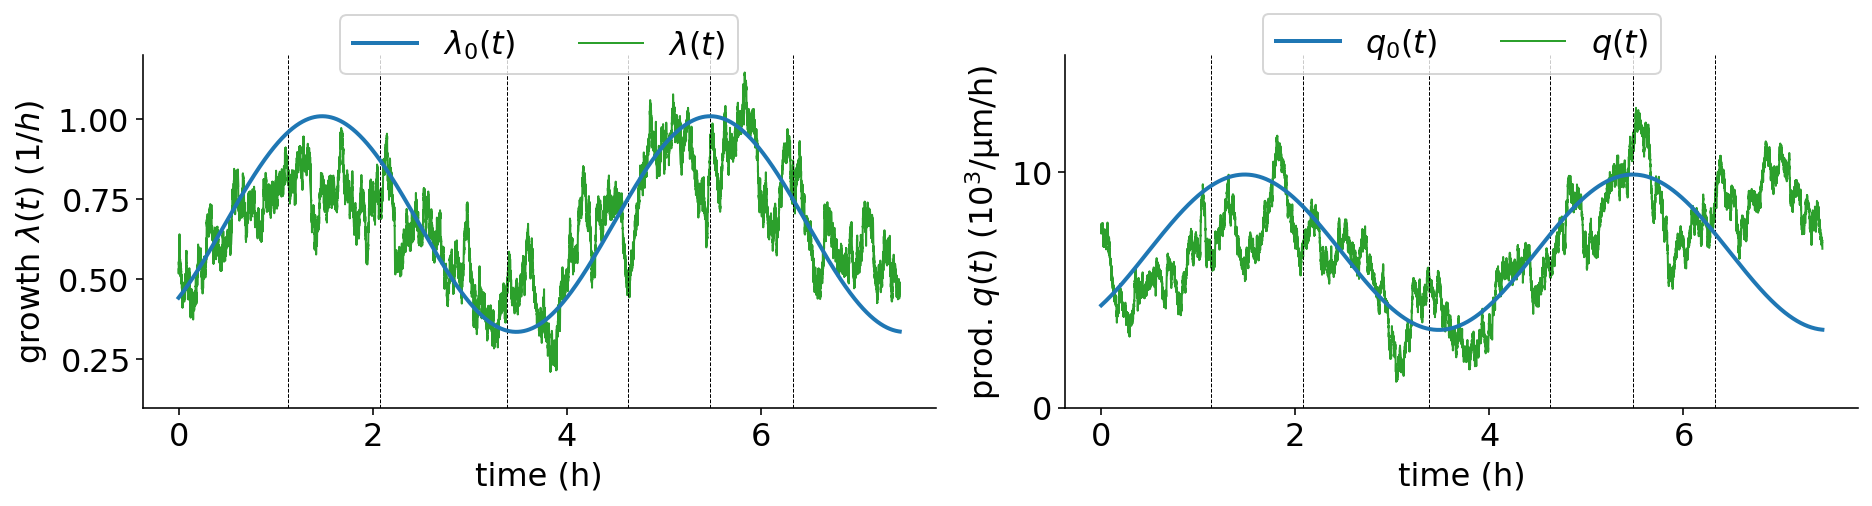

In [13]:
%load_ext autoreload
%autoreload 2



def plot_time_varying_mean( idx_cells, cells_prediction, cells_full, plot_file=None):

    fig, ax = plt.subplots(1, 2, figsize=(FULL_SIZE, FULL_HEIGHT*0.9))
    ax = ax.ravel()
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        # turn off the right spine/ticks
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        # turn off the top spine/ticks
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        a.set_xlabel("time (h)")
    
    time_full_coll = []
    l_full_coll = []
    q_full_coll = []
    
    if cells_full!=None:
        for i, _ in enumerate(cells_full):
            l_full_coll.append(np.array(cells_full[i].lt)  )
            q_full_coll.append(np.array(cells_full[i].qt)/1e3   )
            time_full_coll.append(cells_full[i].time)

    # Plots
    traces_time = index_nested(time_full_coll, idx_cells, True)
    time_shift= traces_time[0]
    # time_shift =0

    time = index_nested(time_full_coll, idx_cells, True)/60.
    mean = np.mean(np.concatenate(l_full_coll))*60
    a = 0.5
    T = 4
    varying_mean = mean*(1+a*np.sin(2*np.pi/T*time))
    ax[0].plot( time - time_shift/60., varying_mean, label=r"$\lambda_0(t)$",
             color='tab:blue',  alpha=1, lw=2, zorder=10)

    mean = np.mean(np.concatenate(q_full_coll))*60
    a = 0.5
    T = 4
    varying_mean = mean*(1+a*np.sin(2*np.pi/T*time))
    ax[1].plot( time - time_shift/60., varying_mean, label=r"$q_0(t)$",
             color='tab:blue',  alpha=1, lw=2, zorder=10)


    ax[0].plot( (index_nested(time_full_coll, idx_cells, True)-time_shift)/60., 
             index_nested(l_full_coll, idx_cells, True)*60., 
                label=r"$\lambda(t)$",
             color='tab:green', alpha=1, lw=1, zorder=1)

    ax[1].plot( (index_nested(time_full_coll, idx_cells, True)-time_shift)/60., 
             index_nested(q_full_coll, idx_cells, True)*60., 
                label=r"$q(t)$",
             color='tab:green', alpha=1, lw=1, zorder=1)





    # cell division
    for i in idx_cells[:-1]:
        for a in ax:
            a.axvline( (cells_prediction[i].time[-1]-time_shift)/60.,color='black', ls='--', lw=0.5)

            a.ticklabel_format(axis='y', style='scientific', scilimits=[-4,4], useMathText=True)

    ax[0].set_ylim([0.1, 1.2])
    ax[1].set_ylim([0, 15])

    ax[0].set_ylabel(r"growth $\lambda(t)$ $(1/h)$")
    ax[1].set_ylabel(r"prod. $q(t)$ ($\mathrm{10^3/\mu m/h}$)") 

    # ax[0].set_title(r"growth rate")
    # ax[1].set_title(r"production rate") 


    ax[0].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=2))
    ax[1].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=2))
    ax[1].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=10))

    for a in ax:
        a.legend( ncol=2, loc="lower center", bbox_to_anchor=(0.5,0.9))

    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()



plot_time_varying_mean(get_longest_path(cells_noise)[:7],
                       cells_prediction,
                       cells_full, 
                       plot_file="../../figures_for_method_paper/supp/nonOU/time_dependent_OU_means.pdf")


